<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">10 · Transformers explained: from attention to BERT</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 4: how the models behind every modern NLP system read text, built up from scratch, then seen inside real BERT</p>

| | |
|---|---|
| **Goal** | Understand (not just use) transformers before fine-tuning them in notebooks 11–12 |
| **Models** | `bert-base-uncased` (general English) · `BiomedBERT` (PubMed) · `Qwen2.5-1.5B` (decoder, already downloaded in nb 09) |
| **Concepts** | RNN/LSTM limits · attention · self-attention (Q, K, V) · scaled dot-product · multi-head · positional encoding · transformer block · encoder vs decoder vs encoder-decoder · pre-training (MLM, next-token) · contextual embeddings · domain pre-training |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoModelForCausalLM, AutoTokenizer, pipeline, logging as hf_logging

from glp1_intel import viz
from glp1_intel.viz import TEXT, TEXT_2, subtitle
from glp1_intel.notebook_style import show

hf_logging.set_verbosity_error()
torch.manual_seed(0)
VIOLETS = plt.cm.colors.LinearSegmentedColormap.from_list("violets", ["#FFFFFF", "#EFEAFF", "#B9A8FF", "#7C5CFF", "#3B2499"])
GENERAL, BIOMED = "bert-base-uncased", "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · Why not just read word by word? RNNs and their limits

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Recurrent networks and long-range dependencies</b>

Before 2017, text models were mostly **recurrent neural networks (RNNs)**: read one word, update a "memory" vector, read the next word…
- **Sequential:** word 50 must wait for words 1–49, so it's slow to train and can't use GPUs fully.
- **Fading memory:** information from early words must survive many updates. Gradients shrink as they flow back (the *vanishing gradient* problem), so long-range links get lost.
- **LSTM / GRU** add *gates* that decide what to keep or forget. Much better, but still sequential, and still strained over hundreds of words.

Example: *"The **patient**, who had tried three other medicines over two years with limited benefit and frequent nausea, finally **stopped**."*
To know **who** stopped, the model must connect words ~20 positions apart. **Attention** connects any two words in one step.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Self-attention, built from scratch

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Query, Key, Value</b>

Every word looks at every other word and decides **how much to borrow from each**. Each word vector **x** is projected three ways:
- **Query (Q)**: what am I looking for?
- **Key (K)**: what do I offer?
- **Value (V)**: what do I actually pass on?

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V$$

1. **Scores** = Q·Kᵀ (how well each query matches each key)
2. **÷ √dₖ** keeps scores from growing with vector size (otherwise softmax becomes too peaked and gradients vanish)
3. **softmax** turns each row into weights that sum to 1
4. Each word's output = **weighted average of all Values**

This is only matrix multiplication, so all words are processed **in parallel**: the transformer's speed advantage.

</div>

In [2]:
def self_attention(X, Wq, Wk, Wv):
    """Scaled dot-product self-attention for one sequence. X: (n_words, d_model)."""
    Q, K, V = X @ Wq, X @ Wk, X @ Wv                  # project every word three ways
    scores = Q @ K.T / np.sqrt(K.shape[1])            # how well each query matches each key
    weights = np.exp(scores - scores.max(axis=1, keepdims=True))
    weights /= weights.sum(axis=1, keepdims=True)     # softmax: each row sums to 1
    return weights @ V, weights                       # weighted average of values

words = ["patient", "stopped", "drug", "nausea"]
rng = np.random.default_rng(0)
d_model, d_k = 8, 4
X = rng.normal(size=(len(words), d_model))            # toy word vectors
Wq, Wk, Wv = (rng.normal(size=(d_model, d_k)) for _ in range(3))
out, W = self_attention(X, Wq, Wk, Wv)

# ── Check against PyTorch's built-in implementation ─────────────────────────
t = lambda a: torch.tensor(a, dtype=torch.float32)
ref = F.scaled_dot_product_attention(t(X @ Wq)[None], t(X @ Wk)[None], t(X @ Wv)[None])[0].numpy()
print("Matches torch.nn.functional.scaled_dot_product_attention:", np.allclose(out, ref, atol=1e-5))
show(pd.DataFrame(W, index=words, columns=words).round(2).reset_index(names="query ↓ / key →"),
     "Attention weights (each row sums to 1)", precision=2)

Matches torch.nn.functional.scaled_dot_product_attention: True


query ↓ / key →,patient,stopped,drug,nausea
patient,0.38,0.13,0.46,0.03
stopped,0.01,0.00,0.13,0.86
drug,0.91,0.00,0.08,0.00
nausea,0.01,0.25,0.08,0.66


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Our 6-line NumPy function gives exactly the same result as PyTorch's optimised version. Each row shows how one word distributes its attention over all words.
With random weights the pattern is meaningless; **training** learns Wq, Wk, Wv so that useful words attend to each other (section 6 shows real BERT).

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Multi-head attention, position, the block</b>

- **Multi-head attention:** run several attention "heads" in parallel (BERT-base: **12 heads × 12 layers**), each with its own Wq/Wk/Wv. One head may track grammar, another coreference ("it" → "Mounjaro"), another nearby words. Outputs are concatenated.
- **Positional encoding:** attention itself ignores order ("drug stopped patient" = "patient stopped drug"), so a position signal is **added** to each word vector. The original transformer used sine and cosine waves of different frequencies; BERT learns position vectors; newer LLMs rotate Q and K (*RoPE*).
- **Transformer block** = multi-head attention → add & normalise → small feed-forward network → add & normalise. *Residual (add)* connections let gradients flow through dozens of stacked blocks.

</div>

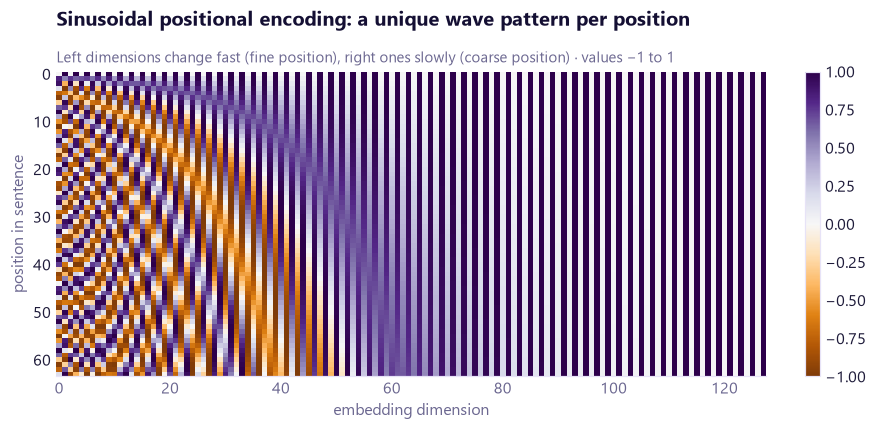

In [3]:
def sinusoidal_positions(n_pos, d):
    pos, i = np.arange(n_pos)[:, None], np.arange(d)[None, :]
    angle = pos / np.power(10000, (2 * (i // 2)) / d)
    return np.where(i % 2 == 0, np.sin(angle), np.cos(angle))

P = sinusoidal_positions(64, 128)
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(P, aspect="auto", cmap="PuOr", vmin=-1, vmax=1)
ax.set_xlabel("embedding dimension"); ax.set_ylabel("position in sentence"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025)
ax.set_title("Sinusoidal positional encoding: a unique wave pattern per position")
subtitle(ax, "Left dimensions change fast (fine position), right ones slowly (coarse position) · values −1 to 1")
viz.save(fig, "10_1_positional_encoding")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Each row is the position vector added to the word at that position. Low dimensions oscillate quickly and high dimensions slowly, like the second, minute and hour hands of a clock, so every position gets a distinct, smoothly varying fingerprint.
The colour scale is **diverging** (orange = negative, purple = positive, white = 0) because the values have a meaningful centre at zero.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · Three families of transformers

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Encoder vs decoder vs encoder–decoder</b>

| Family | Sees | Pre-training task | Examples | Best at |
|---|---|---|---|---|
| **Encoder** | the whole sentence, both directions | **masked language modelling (MLM)**: predict hidden words | BERT, BiomedBERT, RoBERTa | understanding: classification, NER, search |
| **Decoder** | only previous words (*causal mask*) | **next-token prediction** | GPT, Llama, Qwen, Claude | generation: writing, chat, reasoning |
| **Encoder–decoder** | input fully, output left-to-right | denoising / translation | T5, BART | rewriting: translation, summarisation |

**Pre-training** learns general language from huge unlabelled text (self-supervised); **fine-tuning** adapts it to our task with a small labelled set (*transfer learning*, notebook 11).
In this project: encoders (BERT-family) for **classifying and tagging notes**, decoders (LLMs) for **writing** notes and briefs.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · Encoder pre-training: fill in the blank (MLM)

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

BERT was pre-trained by hiding 15% of words and predicting them from **both** sides. So it can already "fill in the blank" with no fine-tuning. Comparing a general and a biomedical model reveals what **domain pre-training** adds.

</div>

In [4]:
prompts = ["Patients on tirzepatide most often reported [MASK] and vomiting.",
           "GLP-1 receptor agonists lower blood [MASK] in type 2 diabetes.",
           "Semaglutide is given as a once-weekly subcutaneous [MASK]."]
rows = []
for name, path in [("BERT (general)", GENERAL), ("BiomedBERT (PubMed)", BIOMED)]:
    fill = pipeline("fill-mask", model=path, top_k=4)
    for p in prompts:
        rows.append({"model": name, "sentence": p,
                     "top predictions": " · ".join(f"{r['token_str']} {r['score']:.0%}" for r in fill(p))})
show(pd.DataFrame(rows).sort_values(["sentence", "model"]), "What each model predicts for [MASK]")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

model,sentence,top predictions
BERT (general),GLP-1 receptor agonists lower blood [MASK] in type 2 diabetes.,pressure 87% · sugar 3% · ph 2% · levels 1%
BiomedBERT (PubMed),GLP-1 receptor agonists lower blood [MASK] in type 2 diabetes.,pressure 63% · glucose 34% · lipids 1% · sugar 1%
BERT (general),Patients on tirzepatide most often reported [MASK] and vomiting.,nausea 100% · headache 0% · fever 0% · hunger 0%
BiomedBERT (PubMed),Patients on tirzepatide most often reported [MASK] and vomiting.,nausea 98% · diarrhea 0% · headache 0% · diarrhoea 0%
BERT (general),Semaglutide is given as a once-weekly subcutaneous [MASK].,injection 28% · treatment 25% · dose 18% · administration 4%
BiomedBERT (PubMed),Semaglutide is given as a once-weekly subcutaneous [MASK].,injection 90% · infusion 3% · dose 2% · tablet 1%


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- Both models know **nausea** goes with vomiting: common English.
- For *"lower blood [MASK] in type 2 diabetes"*, general BERT says **pressure 87%, glucose ~1%**, while BiomedBERT gives **glucose 34%**.
- For *"once-weekly subcutaneous [MASK]"*, BiomedBERT is **90% sure of "injection"** vs 28% for general BERT, which spreads its guesses over *treatment* and *dose*.
- Pre-training on PubMed shifted its knowledge towards medicine, which is why we'll fine-tune a domain model in notebook 11.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Contextual embeddings: the fix for polysemy

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

Word2Vec (notebook 08) gave **one vector per word**. A transformer's output vector for a word depends on the **whole sentence**: *contextual embeddings*. Same word, different meaning → different vector.

</div>

In [5]:
tok = AutoTokenizer.from_pretrained(GENERAL)
bert = AutoModel.from_pretrained(GENERAL, output_attentions=True).eval()

@torch.no_grad()
def word_vector(sentence, word):
    enc = tok(sentence, return_tensors="pt")
    ids = enc["input_ids"][0].tolist()
    return bert(**enc).last_hidden_state[0, ids.index(tok.convert_tokens_to_ids(word))].numpy()

cos = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))
s = {"hospital A": "The patient was ready for discharge from the hospital.",
     "hospital B": "The patient will discharge from the ward tomorrow.",
     "wound":      "The wound showed a yellow discharge and swelling."}
v = {k: word_vector(t, "discharge") for k, t in s.items()}
show(pd.DataFrame([{"pair": "hospital A ↔ hospital B (same meaning)", "cosine": cos(v["hospital A"], v["hospital B"])},
                   {"pair": "hospital A ↔ wound (different meaning)", "cosine": cos(v["hospital A"], v["wound"])}]),
     "Cosine similarity of BERT's vectors for the word 'discharge'", precision=3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

pair,cosine
hospital A ↔ hospital B (same meaning),0.892
hospital A ↔ wound (different meaning),0.533


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The two "leaving hospital" uses get very similar vectors, while the "wound discharge" use is far less similar, even though the word is identical. Word2Vec would give all three the **same** vector.
This is why transformers handle clinical text (where *cold*, *discharge*, *positive*, *stable* are ambiguous) so much better.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · Inside real BERT: what does attention look at?

</div>

Tokens: ['[CLS]', 'the', 'patient', 'stopped', 'mo', '##un', '##jar', '##o', 'because', 'it', 'caused', 'nausea', '.', '[SEP]']
Strongest 'it' → 'Mounjaro' head: layer 9, head 11 (99% of its attention)


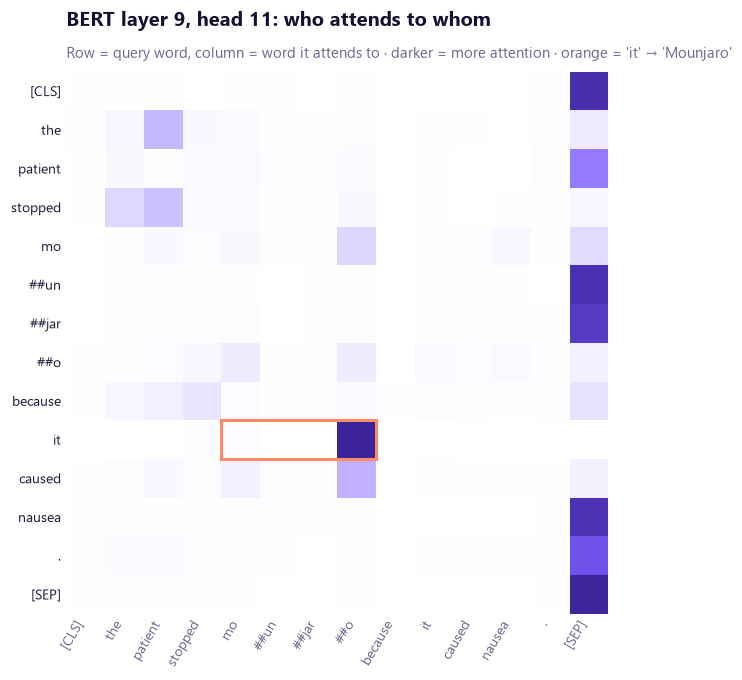

In [6]:
sentence = "The patient stopped Mounjaro because it caused nausea."
enc = tok(sentence, return_tensors="pt")
with torch.no_grad():
    attentions = bert(**enc).attentions                  # 12 layers × (1, 12 heads, n, n)
tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])
i_it = tokens.index("it")
drug = [k for k, t in enumerate(tokens) if t in ("mo", "##un", "##jar", "##o")]

strength = np.array([[attentions[l][0, h, i_it, drug].sum().item() for h in range(12)] for l in range(12)])
layer, head = np.unravel_index(strength.argmax(), strength.shape)
print(f"Tokens: {tokens}")
print(f"Strongest 'it' → 'Mounjaro' head: layer {layer + 1}, head {head + 1} ({strength.max():.0%} of its attention)")

A = attentions[layer][0, head].numpy()
fig, ax = plt.subplots(figsize=(7.5, 6.4))
ax.imshow(A, cmap=VIOLETS, vmin=0, vmax=A.max())
ax.set_xticks(range(len(tokens)), tokens, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(tokens)), tokens, fontsize=9); ax.grid(False)
for side in ("bottom", "left"):
    ax.spines[side].set_visible(False)
ax.add_patch(plt.Rectangle((drug[0] - 0.5, i_it - 0.5), len(drug), 1, fill=False, ec="#FF8A65", lw=2))
ax.set_title(f"BERT layer {layer + 1}, head {head + 1}: who attends to whom")
subtitle(ax, "Row = query word, column = word it attends to · darker = more attention · orange = 'it' → 'Mounjaro'")
viz.save(fig, "10_2_attention_head")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- WordPiece splits **Mounjaro** into `mo ##un ##jar ##o` (BERT has never seen the brand).
- In **layer 9, head 11**, the word **"it"** puts almost **all** of its attention on Mounjaro (orange box), specifically its **last piece `##o`**: models often gather a split word's meaning on its final sub-word token. Nobody taught BERT pronouns: this **coreference head** emerged from pre-training alone.
- Most of the 144 heads do something else (attend to neighbours, punctuation, `[CLS]`/`[SEP]`). That's why multi-head attention matters: each head specialises.
- Note that we *searched* all 144 heads for the one that best matches our idea, so a single striking head is an **illustration**, not proof of how the model decides (see the caution below).

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out · Attention ≠ explanation</b>

Attention heatmaps are tempting explanations, but research shows attention weights are **not** a faithful explanation of predictions: other heads, value vectors and later layers change what reaches the output.
Use them to **illustrate** how transformers work, and use proper attribution methods (e.g. integrated gradients) plus error analysis to explain specific predictions.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 7 · Decoder pre-training: predict the next token

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

A decoder (GPT, Llama, Qwen, Claude) is trained to predict the **next token** given only previous ones (a *causal mask* hides the future).
Generation repeats this: predict a distribution → **sample** a token → append → repeat. The sampling settings we used in notebook 09 act on exactly this distribution:
- **Temperature** divides the logits before softmax: < 1 sharpens (safer), > 1 flattens (more varied)
- **Top-p** keeps only the smallest set of tokens covering p of the probability

</div>

In [7]:
qtok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")                 # downloaded in notebook 09
qwen = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct", dtype=torch.float32).eval()

context = "The most common side effects of GLP-1 medicines are nausea, vomiting and"
with torch.no_grad():
    logits = qwen(**qtok(context, return_tensors="pt")).logits[0, -1]
rows = []
for T in (0.5, 1.0, 1.5):
    probs = torch.softmax(logits / T, dim=-1)
    top = torch.topk(probs, 5)
    rows.append({"temperature": T, "top-5 next tokens": " · ".join(f"{qtok.decode(i).strip()!r} {p:.0%}" for p, i in zip(top.values, top.indices)),
                 "probability of top token": float(top.values[0])})
show(pd.DataFrame(rows), f"Next-token distribution after: “{context} …”", precision=2)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

temperature,top-5 next tokens,probability of top token
0.50,'diarrhea' 89% · 'diarr' 9% · 'abdominal' 2% · 'loss' 0% · 'loose' 0%,0.89
1.00,'diarrhea' 55% · 'diarr' 17% · 'abdominal' 8% · 'loss' 2% · 'loose' 2%,0.55
1.50,'diarrhea' 23% · 'diarr' 10% · 'abdominal' 6% · 'loss' 3% · 'loose' 2%,0.23


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The model predicts plausible continuations (e.g. *diarrhea*, *constipation*) from pre-training alone.
**Lower temperature** concentrates probability on the top token (predictable text); **higher temperature** spreads it out (more variety, more risk of nonsense). That's the dial we set to 0.8 for synthetic notes.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 8 · Summary

</div>

In [8]:
sizes = pd.DataFrame([
    {"model": "BERT-base / BiomedBERT", "type": "encoder", "parameters_m": sum(p.numel() for p in bert.parameters()) / 1e6, "layers": 12, "heads": 12},
    {"model": "Qwen2.5-1.5B-Instruct", "type": "decoder", "parameters_m": sum(p.numel() for p in qwen.parameters()) / 1e6,
     "layers": qwen.config.num_hidden_layers, "heads": qwen.config.num_attention_heads},
    {"model": "Qwen2.5-7B-Instruct (nb 09, Colab)", "type": "decoder", "parameters_m": 7_600, "layers": 28, "heads": 28},
])
show(sizes, "Models used in this project", precision=0)

model,type,parameters_m,layers,heads
BERT-base / BiomedBERT,encoder,109,12,12
Qwen2.5-1.5B-Instruct,decoder,"1,544",28,12
"Qwen2.5-7B-Instruct (nb 09, Colab)",decoder,"7,600",28,28


<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. Demos use **single sentences**; real behaviour varies with context and length (BERT's limit: 512 tokens).
2. Fill-mask percentages show what a model *expects*, not medical truth.
3. Attention heatmaps illustrate the mechanism; they don't explain predictions.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** self-attention implemented and verified against PyTorch, positional encoding, the three transformer families, MLM vs next-token pre-training, contextual embeddings and real attention heads.
**Next:** notebook 11 **fine-tunes** BERT vs BiomedBERT on our visit notes and ADE Corpus, and must beat the TF-IDF baseline from notebook 07.

**Interview questions you can now answer**
- *Why did transformers replace RNNs?* Parallel processing and direct long-range connections through attention; no vanishing gradients through time.
- *Explain Q, K, V.* Query = what I look for, Key = what I offer, Value = what I pass on; output = softmax(QKᵀ/√dₖ)·V.
- *Why divide by √dₖ?* Large dot products saturate softmax and kill gradients.
- *Why positional encoding?* Attention is order-blind; positions are added (sinusoidal, learned or rotary).
- *Encoder vs decoder?* Bidirectional understanding (MLM) vs left-to-right generation (next token); BERT vs GPT.
- *What are contextual embeddings?* Vectors that depend on the sentence, fixing Word2Vec's one-vector-per-word problem.
- *Does attention explain a prediction?* Not reliably; use attribution and error analysis.

</div>